In [1]:
import sys, yaml
sys.path.append("../..")

import numpy as np
import torch

In [2]:
from sklearn.neighbors import BallTree
from torchgeo_bench.coordbench.spatiotemporal_idw import (
    knn_predict_multi, pairwise_haversine_plus_time_chunked)

# Simple test with artificial lat, lon, time

In [3]:
rng = np.random.default_rng(0)
n = 3000
lat, lon, t = rng.uniform(25, 50, n), rng.uniform(-125, -65, n), rng.uniform(0, 365, n)
y = np.sin(np.radians(lat) * 4) + np.cos(np.radians(lon) * 3) + np.sin(t / 50)
tr, te = slice(0, 2400), slice(2400, None)

### Set time to 0, make sure they match sklearns haversine BallTree

In [4]:
S  = np.c_[lat[tr], lon[tr], np.zeros(2400)]
S0 = np.c_[lat[te], lon[te], np.zeros(600)]
d, i = pairwise_haversine_plus_time_chunked(S, S0, k=5, device="cpu")
d_ref, i_ref = BallTree(np.radians(S[:, :2]), metric="haversine").query(np.radians(S0[:, :2]), k=5)
assert d.shape == (600, 5)
print(np.allclose(d, d_ref * 6371.0, atol=1e-1))   # km; float32 tolerance

True


Reset

In [5]:
S  = np.c_[lat[tr], lon[tr], t[tr]]
S0 = np.c_[lat[te], lon[te], t[te]]

### k=1 self-lookup returns each training point's own label

In [6]:
p = knn_predict_multi(lat[tr], lon[tr], t[tr], y[tr], lat[tr], lon[tr], t[tr], (1,), "regression", 0, 1.0)
print(np.allclose(p[1], y[tr]))

True


### Look at scales of haversine distance and time distance

In [7]:
dist_haversine, dist_time = pairwise_haversine_plus_time_chunked(S, S0, k=5, device="cpu", return_separate=True)
print(f"Haversine Distance: Max: {dist_haversine.max()}; Min: {dist_haversine.min()}; Mean: {dist_haversine.mean()}; Median: {np.median(dist_haversine)}")
print(f"Time Distance: Max: {dist_time.max()}; Min: {dist_time.min()}; Mean: {dist_time.mean()}; Median: {np.median(dist_time)}")

Haversine Distance: Max: 170.786376953125; Min: 0.8425188064575195; Mean: 71.40243530273438; Median: 71.28350830078125
Time Distance: Max: 1.2124100923538208; Min: 0.0001220703125; Mean: 0.22714181244373322; Median: 0.1910247802734375


### See if using time in spatiotemporal IDW beats spatial only IDW (with c=0)

In [9]:
from sklearn.metrics import r2_score
for c in (0.0, 0.1, 1.0, 10.0, 100.0, 1000.0, 10000.0):
    p = knn_predict_multi(lat[tr], lon[tr], t[tr], y[tr], lat[te], lon[te], t[te], (1, 5, 10, 20), "regression", 0, c)
    print(c, {k: round(r2_score(y[te], v), 3) for k, v in p.items()})

0.0 {1: 0.686, 5: 0.775, 10: 0.751, 20: 0.712}
0.1 {1: 0.686, 5: 0.775, 10: 0.751, 20: 0.712}
1.0 {1: 0.686, 5: 0.775, 10: 0.751, 20: 0.712}
10.0 {1: 0.686, 5: 0.775, 10: 0.751, 20: 0.712}
100.0 {1: 0.686, 5: 0.775, 10: 0.751, 20: 0.712}
1000.0 {1: 0.686, 5: 0.775, 10: 0.751, 20: 0.712}
10000.0 {1: 0.686, 5: 0.775, 10: 0.751, 20: 0.712}


# Visualizations

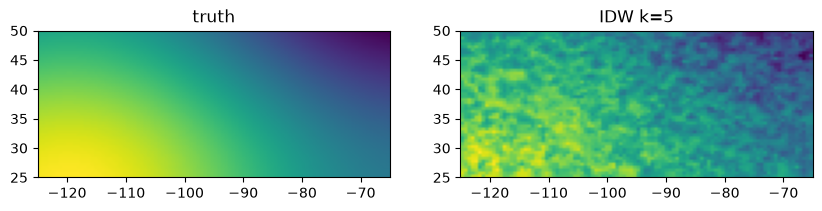

In [7]:
import matplotlib.pyplot as plt

day = 100.0
glat, glon = np.meshgrid(np.linspace(25, 50, 50), np.linspace(-125, -65, 100), indexing="ij")
pred = knn_predict_multi(lat, lon, t, y, glat.ravel(), glon.ravel(), np.full(glat.size, day),
                         (5,), "regression", 0, 1e2)[5]
truth = np.sin(np.radians(glat) * 4) + np.cos(np.radians(glon) * 3) + np.sin(day / 50)

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
for a, img, title in zip(ax, (truth, pred.reshape(glat.shape)), ("truth", "IDW k=5")):
    a.imshow(img, origin="lower", extent=(-125, -65, 25, 50)); a.set_title(title)
plt.show()


# Try on real datasets

In [8]:
import numpy as np, matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from torchgeo_bench.coordbench.datasets import (
    load_daily_usa_electric_usage, load_era5_ecmwf, load_chelsa_monthly)

For now, use a subsample

exact kNN is O(N_test * N_train)

In [9]:
rng = np.random.default_rng(0)
N = 200_000

In [10]:
def prep(b, target, group=None):
    idx = rng.choice(len(b.lat), min(N, len(b.lat)), replace=False)
    idx = idx[np.isfinite(b.tasks[target][idx])]  # drop NaN/inf labels before splitting
    lat, lon, t = b.lat[idx], b.lon[idx], b.posix_timestamp[idx]
    if group is None:  # one group per unique location
        group = np.unique(np.c_[lat, lon], axis=0, return_inverse=True)[1].ravel()
    else:
        group = group[idx]
    test_g = rng.choice(np.unique(group), len(np.unique(group)) // 5, replace=False)
    test = np.isin(group, test_g)
    return dict(name=b.name, lat=lat, lon=lon, t=t, tasks={target: b.tasks[target][idx]}, test=test)


In [11]:
elec = load_daily_usa_electric_usage(subsample_locations=True)[0]
era5 = load_era5_ecmwf(subsample_locations=True)[0]
chelsa = load_chelsa_monthly(subsample_locations=True)[0]


/home/libe2152/projects/torchgeo-bench/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/libe2152/projects/torchgeo-bench/src/torchgeo_bench/coordbench/datasets.py:392: RuntimeWarning: divide by zero encountered in log
  tasks[f"{task_name}_log"] = np.log(df[task_name].to_numpy(np.float64))
/home/libe2152/projects/torchgeo-bench/src/torchgeo_bench/coordbench/datasets.py:392: RuntimeWarning: divide by zero encountered in log
  tasks[f"{task_name}_log"] = np.log(df[task_name].to_numpy(np.float64))
/home/libe2152/projects/torchgeo-bench/src/torchgeo_bench/coordbench/datasets.py:392: RuntimeWarning: invalid value encountered in log
  tasks[f"{task_name}_log"] = np.log(df[task_name].to_numpy(np.float64))


In [12]:
data = (
    [prep(elec, t, elec.spatial_aggregation_key[1].to_numpy()) for t in elec.tasks]
    + [prep(era5, "t2m")]
    + [prep(chelsa, "hurs")]
)

In [13]:
KS, CS = (5, 20), (0.0, 1e2, 1e4)  # c=0 is spatial-only IDW
rows, preds = [], {}
for d in data:
    tr, te = ~d["test"], d["test"]
    for task, y in d["tasks"].items():
        for c in CS:
            p = knn_predict_multi(d["lat"][tr], d["lon"][tr], d["t"][tr], y[tr],
                                  d["lat"][te], d["lon"][te], d["t"][te], KS, "regression", 0, c)
            for k in KS:
                print(f"{d['name']} {task} k={k} c={c:g}")
                rows.append((d["name"], task, f"idw k={k} c={c:g}", r2_score(y[te], p[k])))
            preds[(d["name"], task, c)] = p[20]

usa_daily_electric_load_2016_from_centroid median k=5 c=0
usa_daily_electric_load_2016_from_centroid median k=20 c=0
usa_daily_electric_load_2016_from_centroid median k=5 c=100
usa_daily_electric_load_2016_from_centroid median k=20 c=100
usa_daily_electric_load_2016_from_centroid median k=5 c=10000
usa_daily_electric_load_2016_from_centroid median k=20 c=10000
usa_daily_electric_load_2016_from_centroid median_log k=5 c=0
usa_daily_electric_load_2016_from_centroid median_log k=20 c=0
usa_daily_electric_load_2016_from_centroid median_log k=5 c=100
usa_daily_electric_load_2016_from_centroid median_log k=20 c=100
usa_daily_electric_load_2016_from_centroid median_log k=5 c=10000
usa_daily_electric_load_2016_from_centroid median_log k=20 c=10000
era5_ecmwf t2m k=5 c=0
era5_ecmwf t2m k=20 c=0
era5_ecmwf t2m k=5 c=100
era5_ecmwf t2m k=20 c=100
era5_ecmwf t2m k=5 c=10000
era5_ecmwf t2m k=20 c=10000
chelsa hurs k=5 c=0
chelsa hurs k=20 c=0
chelsa hurs k=5 c=100
chelsa hurs k=20 c=100
chelsa hurs

In [14]:
from torchgeo_bench.coordbench.models import ClimplicitLocationEncoder, TemporalSatCLIPEncoder
from torchgeo_bench.coordbench.probe import linear_probe_score

In [21]:
import os
os.environ["SATCLIP_HOME"] = os.path.expanduser("~/projects/temporal-satclip")
os.environ["CKPT_HOME"] = os.path.expanduser("~/projects/temporal-satclip/ckpts")


In [22]:
encoders = {
    "climplicit": ClimplicitLocationEncoder(device="cuda"),
    "t-satclip": TemporalSatCLIPEncoder("t_satclip-ckpts/tsatclip-doy-1M.ckpt",  # path from conf/model/t_satclip/t_satclip_doy_1M.yaml
                                        model_name="tsatclip/doy", device="cuda"),
}
for d in data:
    for enc_name, enc in encoders.items():
        X = enc.encode(d["lon"], d["lat"], d["t"])
        for task, y in d["tasks"].items():
            score, _ = linear_probe_score(X, y, "regression", test_mask=d["test"], device="cuda")
            rows.append((d["name"], task, enc_name, score))

using pretrained moco vit16
using loss function: satclip_loss
using temporal model: True


/home/libe2152/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:243: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)
/home/libe2152/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:243: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)
/home/libe2152/projects/torchgeo-bench/src/torchgeo_bench/coordbench/probe.py:243: UserWarning: ridge alpha selected at grid edge; widen RIDGE_ALPHAS
  best_alpha, _ = _cv_alpha_scores(data, inner, alphas, standardize=standardize)


## Visualization

In [23]:
import pandas as pd
df = pd.DataFrame(rows, columns=["dataset", "task", "method", "r2"])
print(df.pivot_table(index=["dataset", "task"], columns="method", values="r2").round(3))

method                                                 climplicit  \
dataset                                    task                     
chelsa                                     hurs             0.592   
era5_ecmwf                                 t2m              0.529   
usa_daily_electric_load_2016_from_centroid median           0.129   
                                           median_log       0.203   

method                                                 idw k=20 c=0  \
dataset                                    task                       
chelsa                                     hurs               0.700   
era5_ecmwf                                 t2m                0.852   
usa_daily_electric_load_2016_from_centroid median            -1.381   
                                           median_log         0.097   

method                                                 idw k=20 c=100  \
dataset                                    task                         
chelsa      

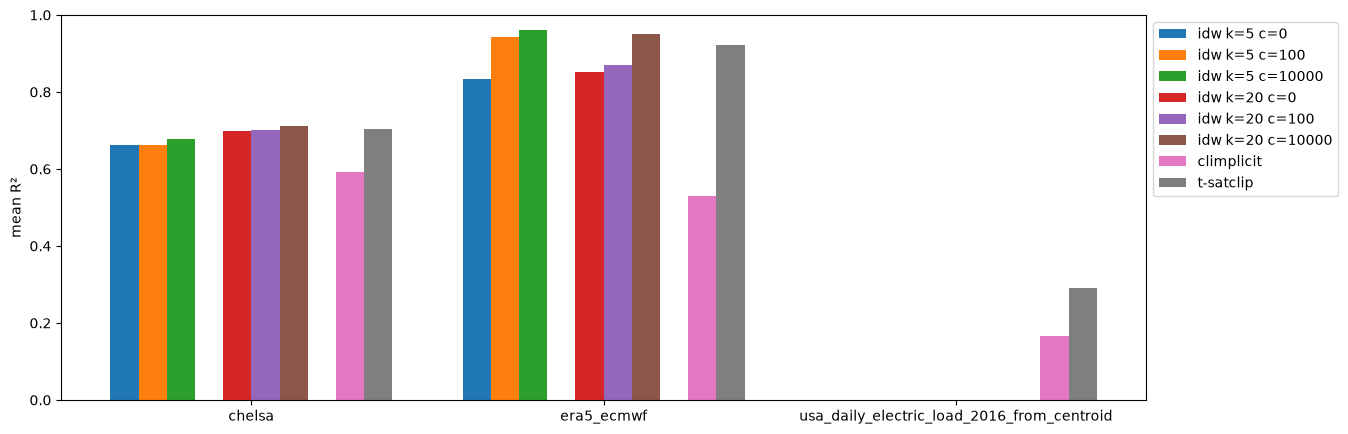

In [33]:
r2 = df.groupby(["dataset", "method"]).r2.mean().unstack()
groups = r2.columns.str.extract(r"(k=\d+)", expand=False).fillna("encoders")  # group key per method
order = sorted(set(groups), key=lambda g: (g == "encoders", int(g[2:]) if g != "encoders" else 0))

w, gap = 0.8 / (len(r2.columns) + len(order) - 1), 1  # gap = blank bar slots between groups
fig, ax = plt.subplots(figsize=(14, 5))
pos = 0
for g in order:
    for m in r2.columns[groups == g]:
        ax.bar(np.arange(len(r2)) + pos * w, r2[m], w, label=m)
        pos += 1
    pos += gap
ax.set_xticks(np.arange(len(r2)) + (pos - gap - 1) * w / 2, r2.index)
ax.set_ylabel("mean R²"); ax.set_ylim(0, 1)
ax.legend(bbox_to_anchor=(1, 1), loc="upper left")
plt.show()


IDW is really bad on electrical load...

In [28]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

In [ ]:
plt.rcParams.update({"font.size": 14})

In [31]:
def plot_idw_map(d, task, p):
    te = d["test"]
    lat, lon, t, y = d["lat"][te], d["lon"][te], d["t"][te], d["tasks"][task][te]
    s = t == pd.Series(t).mode()[0]  # timestamp with the most held-out points
    err = p[s] - y[s]
    vmin, vmax = np.percentile(y[s], [2, 98])
    emax = np.percentile(np.abs(err), 98)
    day = pd.to_datetime(t[s][0], unit="s").date()

    fig, ax = plt.subplots(3, 1, figsize=(12, 18), subplot_kw=dict(projection=ccrs.PlateCarree()))
    for a, v, title, kw in zip(
        ax, (y[s], p[s], err), ("truth", "IDW", "IDW − truth"),
        (dict(cmap="viridis", vmin=vmin, vmax=vmax),) * 2 + (dict(cmap="RdBu_r", vmin=-emax, vmax=emax),),
    ):
        a.add_feature(cfeature.LAND, color="0.92")
        a.coastlines(lw=0.5)
        a.add_feature(cfeature.BORDERS, lw=0.3)
        im = a.scatter(lon[s], lat[s], c=v, s=15, transform=ccrs.PlateCarree(), **kw)
        a.set_extent([lon.min() - 2, lon.max() + 2, lat.min() - 2, lat.max() + 2], ccrs.PlateCarree())
        a.set_title(f"{title}  (n={s.sum()})")
        fig.colorbar(im, ax=a, shrink=0.8)
    fig.suptitle(f"{d['name']} · {task} · {day}", fontsize=16)
    fig.tight_layout()
    plt.show()

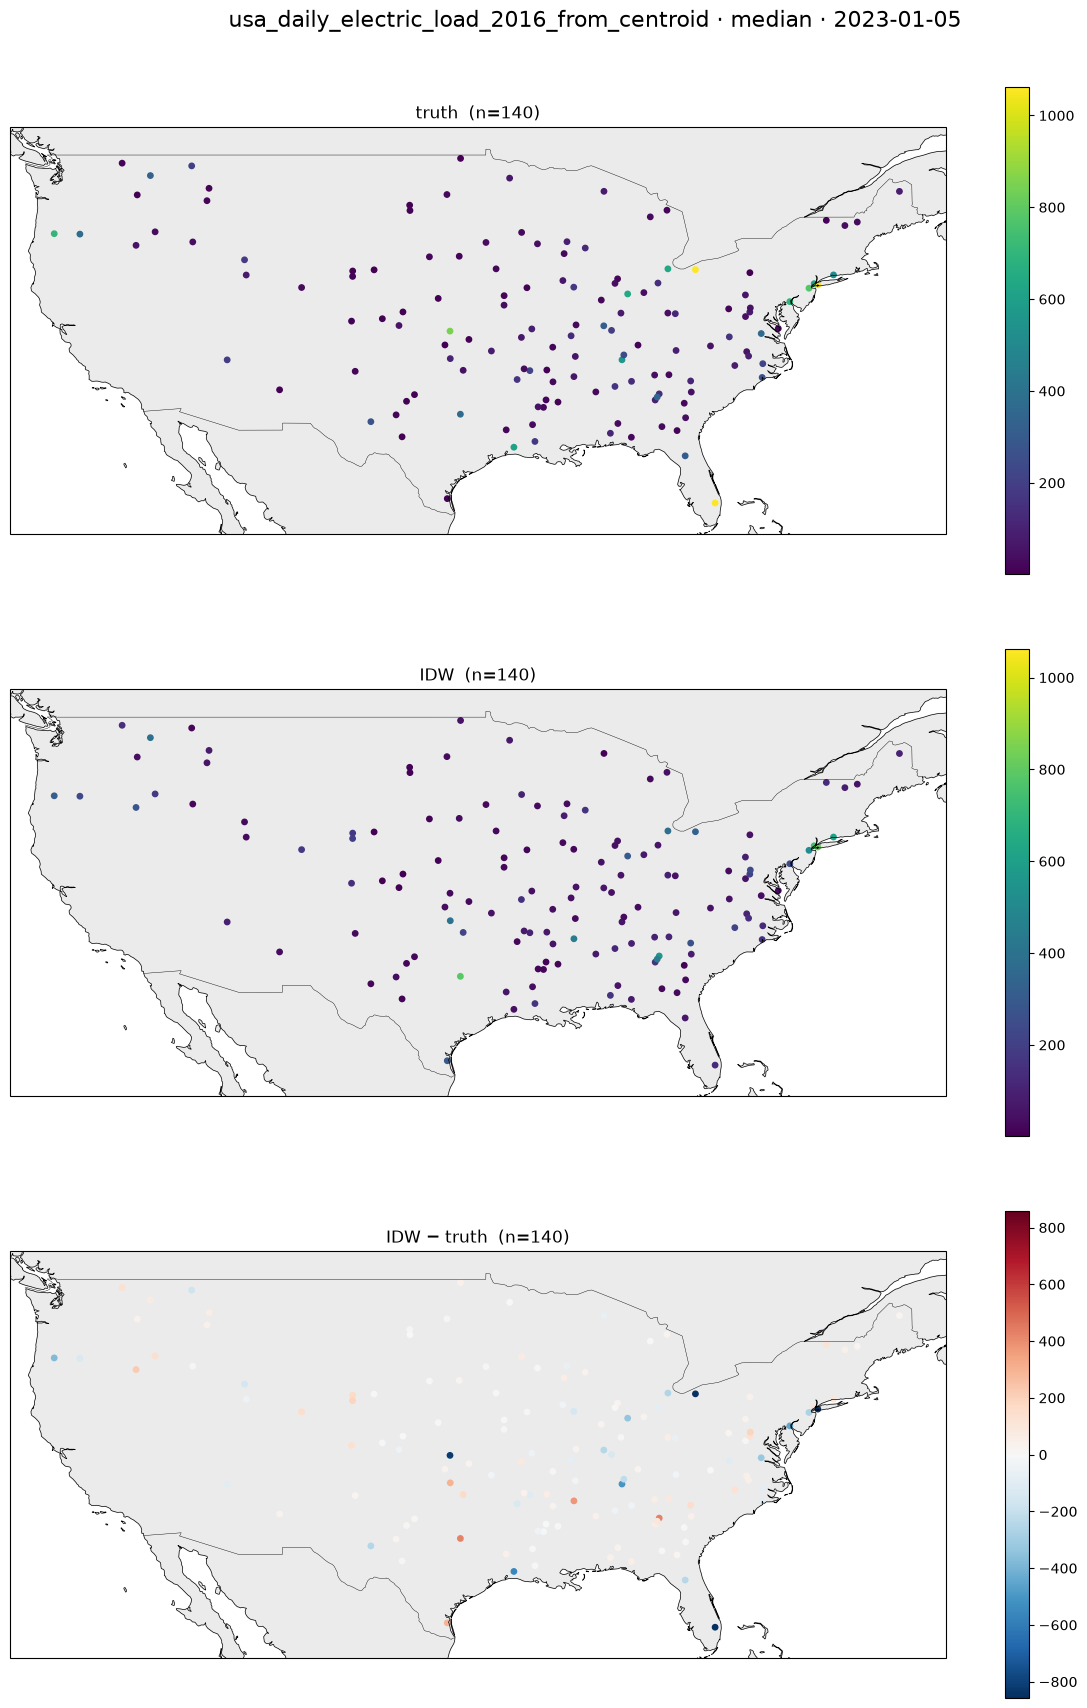

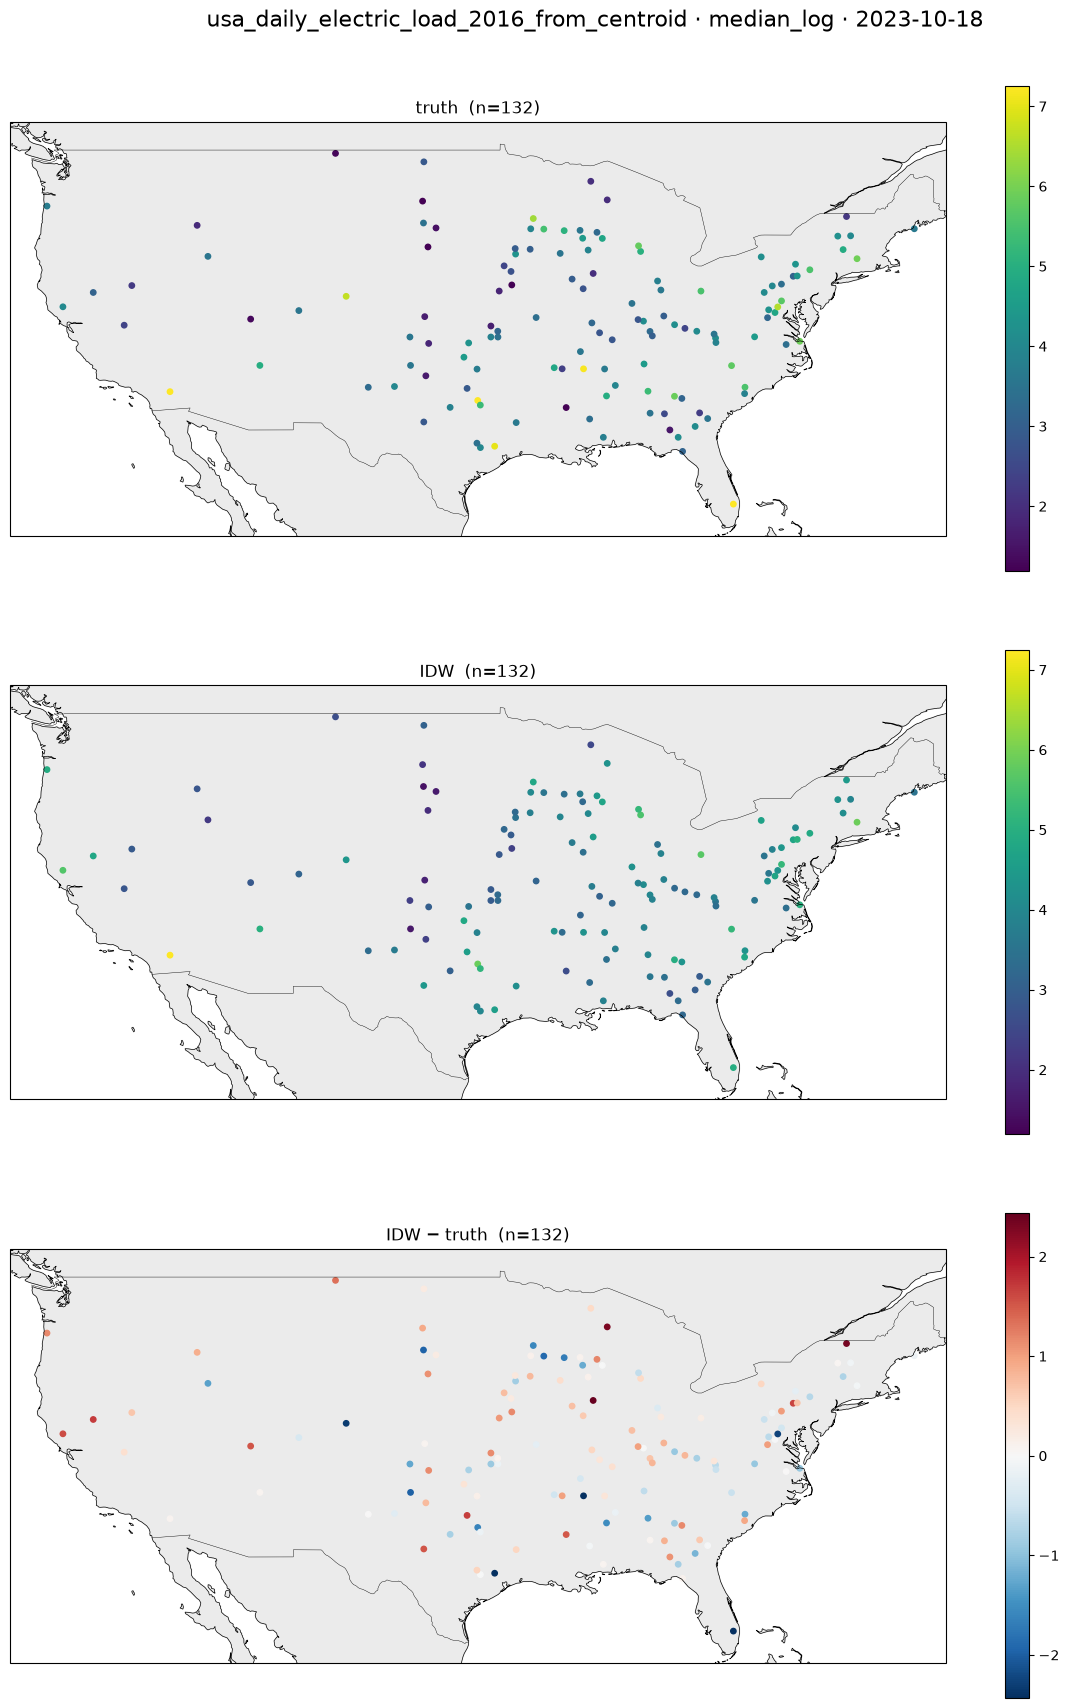

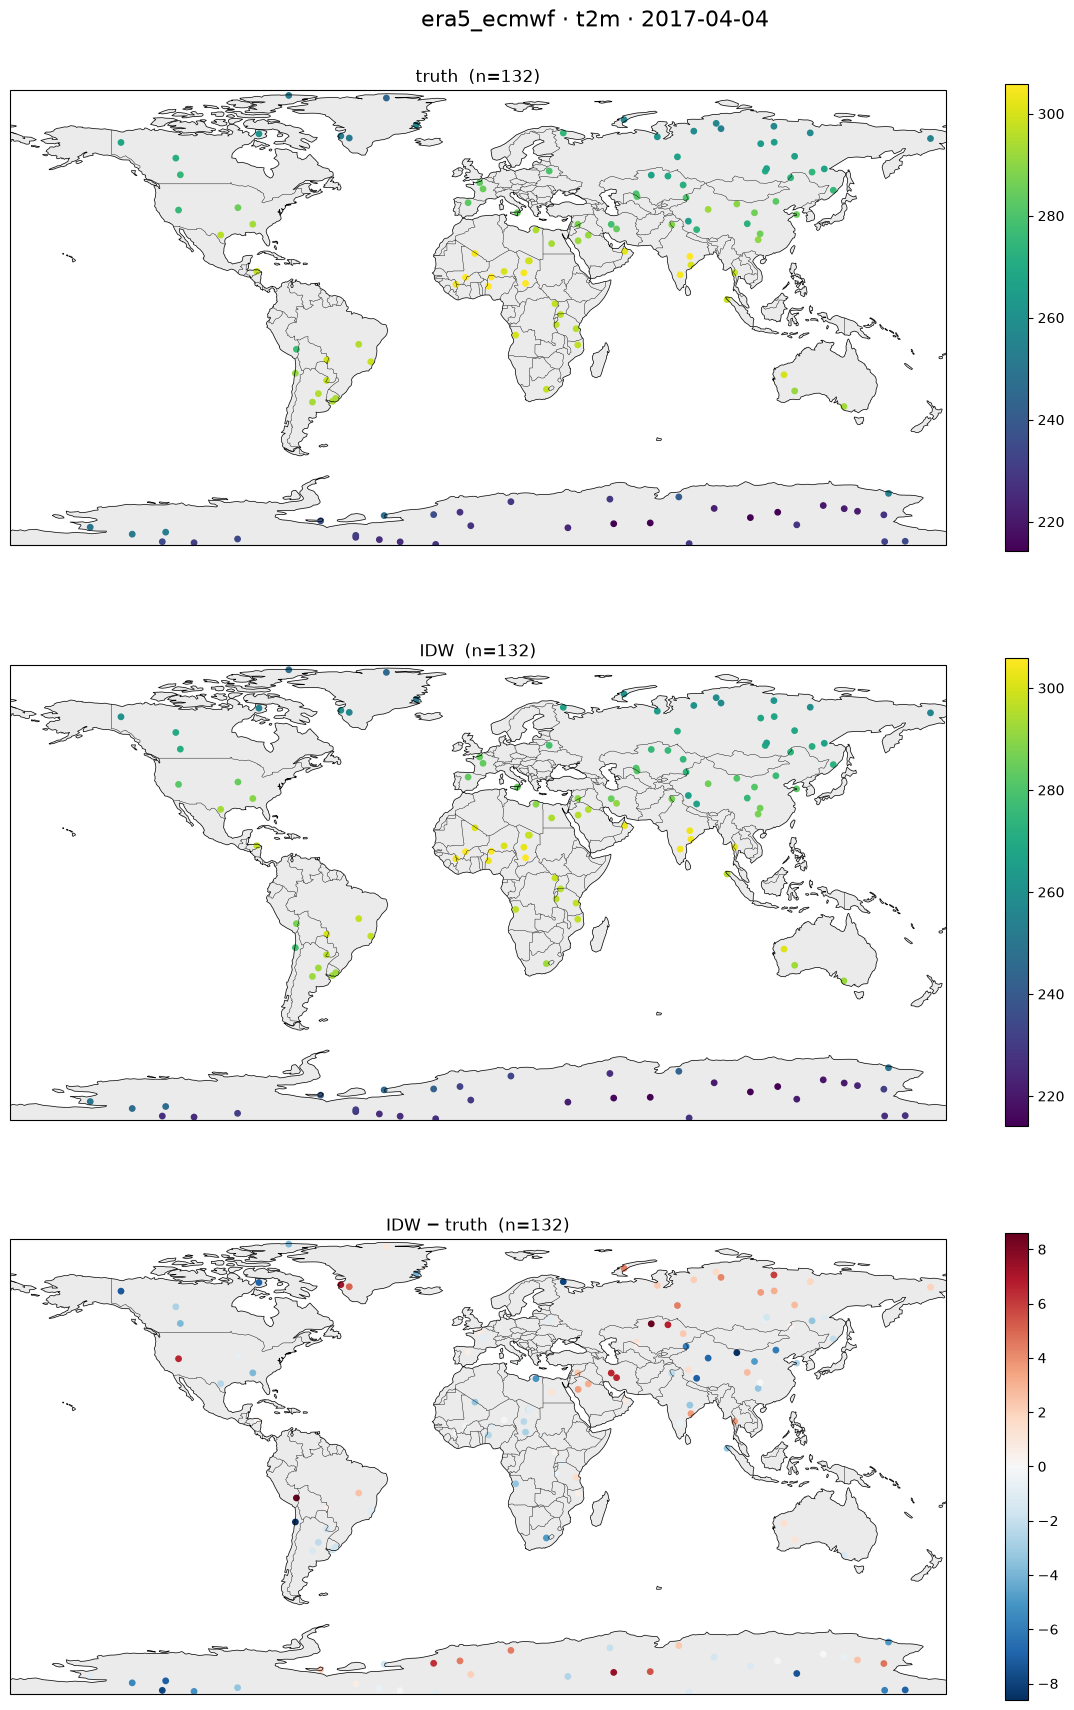

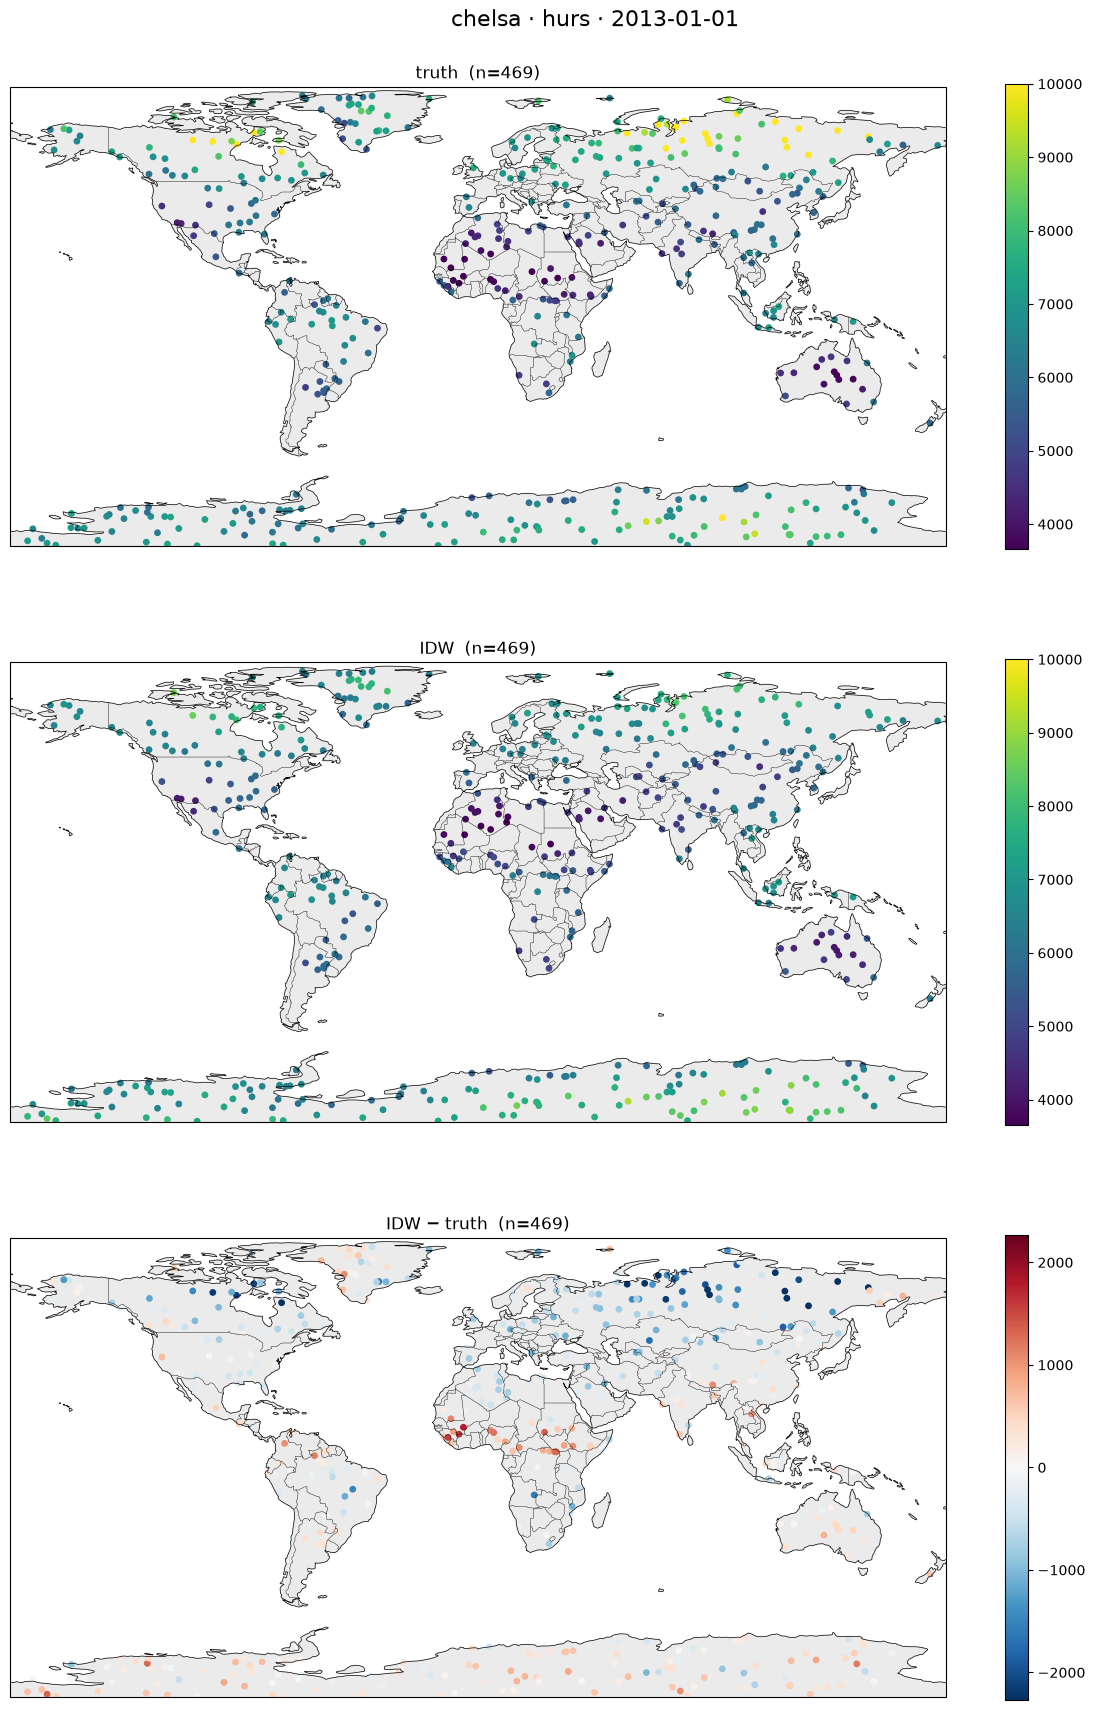

In [32]:
c, k = 1e6, 20
for d in data:
    task = next(iter(d["tasks"]))
    y, tr, te = d["tasks"][task], ~d["test"], d["test"]
    p = knn_predict_multi(d["lat"][tr], d["lon"][tr], d["t"][tr], y[tr],
                          d["lat"][te], d["lon"][te], d["t"][te], (k,), "regression", 0, c)[k]
    plot_idw_map(d, task, p)